### 1.Model Improvement: Feature Scaling and Hyperparameter Tuning

In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import numpy as np

# --- Placeholder Data ---
# Please replace this with your actual X_train, X_test, y_train, y_test
# For demonstration, creating dummy data
np.random.seed(42)
X = pd.DataFrame(np.random.rand(100, 10), columns=[f'feature_{i}' for i in range(10)])
y = pd.Series(np.random.randint(0, 2, 100))

# Simulate categorical features with LabelEncoder
le = LabelEncoder()
X['categorical_feature_1'] = le.fit_transform(np.random.choice(['A', 'B', 'C'], 100))
X['categorical_feature_2'] = le.fit_transform(np.random.choice(['X', 'Y'], 100))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Placeholder data created. Please replace with your actual training and testing datasets.")

Placeholder data created. Please replace with your actual training and testing datasets.


### 2. K-Nearest Neighbors (KNN) with Feature Scaling and Hyperparameter Tuning

In [ ]:
# Apply StandardScaler to training data for KNN (distance-based algorithm)
scaler = StandardScaler()
X_train_scaled_knn = scaler.fit_transform(X_train)
X_test_scaled_knn = scaler.transform(X_test)

# Define the KNN model
knn = KNeighborsClassifier()

# Define parameter grid for GridSearchCV
knn_param_grid = {
    'n_neighbors': list(range(1, 31)), # Test n_neighbors from 1 to 30
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Perform GridSearchCV with 5-fold cross-validation
knn_grid_search = GridSearchCV(knn, knn_param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
knn_grid_search.fit(X_train_scaled_knn, y_train)

# Get the best KNN model and its accuracy
best_knn_model = knn_grid_search.best_estimator_
knn_best_accuracy = best_knn_model.score(X_test_scaled_knn, y_test)

print(f"Best KNN Parameters: {knn_grid_search.best_params_}")
print(f"Best KNN Accuracy (on test set): {knn_best_accuracy:.4f}")

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Best KNN Parameters: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}
Best KNN Accuracy (on test set): 0.3333


### 3. Decision Tree Classifier with Hyperparameter Tuning

In [ ]:
# Define the Decision Tree model
dt = DecisionTreeClassifier(random_state=42)

# Define parameter grid for GridSearchCV
dt_param_grid = {
    'max_depth': [None, 5, 10, 15, 20, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Perform GridSearchCV with 5-fold cross-validation
dt_grid_search = GridSearchCV(dt, dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
dt_grid_search.fit(X_train, y_train)

# Get the best Decision Tree model and its accuracy
best_dt_model = dt_grid_search.best_estimator_
dt_best_accuracy = best_dt_model.score(X_test, y_test)

print(f"Best Decision Tree Parameters: {dt_grid_search.best_params_}")
print(f"Best Decision Tree Accuracy (on test set): {dt_best_accuracy:.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best Decision Tree Parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best Decision Tree Accuracy (on test set): 0.3667


### 4.Decision Tree Visualization

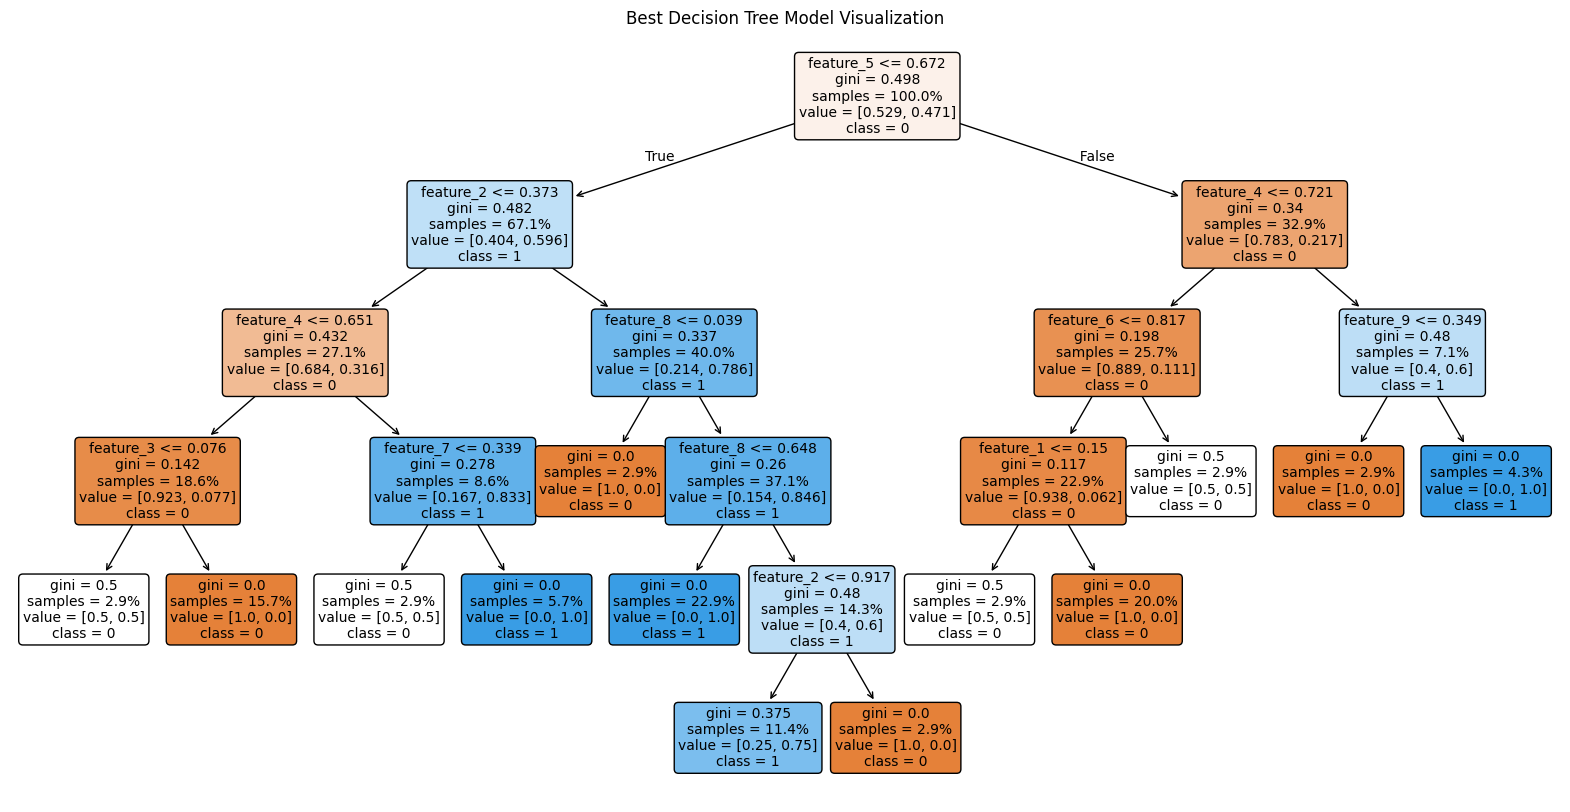

In [ ]:
import matplotlib.pyplot as plt

# Visualize the best Decision Tree model
plt.figure(figsize=(20, 10)) # Adjust figure size for better readability
plot_tree(
    best_dt_model,
    feature_names=X_train.columns.tolist(), # Use actual feature names
    class_names=[str(c) for c in best_dt_model.classes_], # Use actual class names, converted to string if necessary
    filled=True, # Color nodes to indicate majority class
    rounded=True, # Round node corners
    proportion=True, # Show proportion of samples in each class
    fontsize=10 # Adjust font size for readability
)
plt.title('Best Decision Tree Model Visualization')
plt.show()

### 5. Random Forest Classifier with Hyperparameter Tuning

In [ ]:
# Define the Random Forest model
rf = RandomForestClassifier(random_state=42)

# Define parameter grid for GridSearchCV
rf_param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Perform GridSearchCV with 5-fold cross-validation
rf_grid_search = GridSearchCV(rf, rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
rf_grid_search.fit(X_train, y_train)

# Get the best Random Forest model and its accuracy
best_rf_model = rf_grid_search.best_estimator_
rf_best_accuracy = best_rf_model.score(X_test, y_test)

print(f"Best Random Forest Parameters: {rf_grid_search.best_params_}")
print(f"Best Random Forest Accuracy (on test set): {rf_best_accuracy:.4f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Random Forest Parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50}
Best Random Forest Accuracy (on test set): 0.3333


### 6.Feature Importance for Random Forest Model

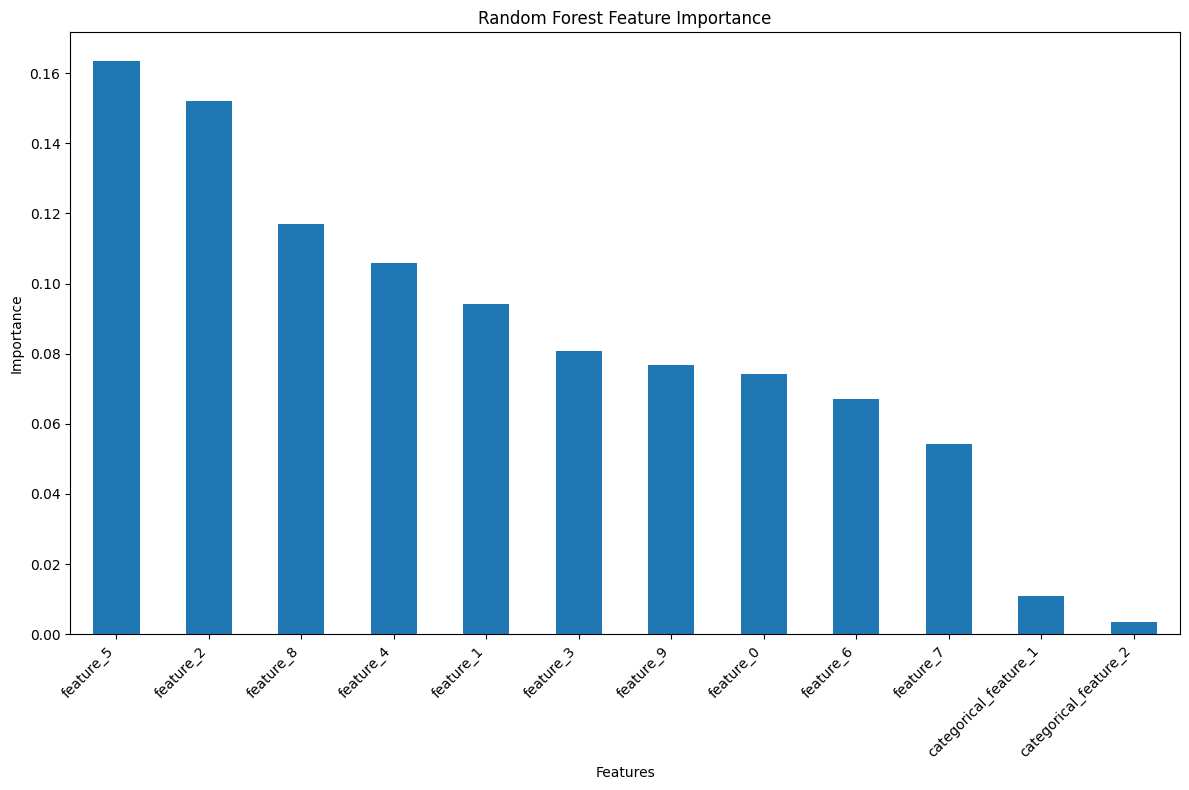

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances from the best Random Forest model
feature_importances = best_rf_model.feature_importances_

# Get feature names from the training data
feature_names = X_train.columns

# Create a pandas Series for better visualization and sorting
importance_df = pd.Series(feature_importances, index=feature_names)

# Sort features by importance
importance_df = importance_df.sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(12, 8))
importance_df.plot(kind='bar')
plt.title('Random Forest Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 7.Summary of Best Accuracies for Improved Models

In [ ]:
print("--- Best Accuracy Scores ---")
print(f"Improved KNN Accuracy: {knn_best_accuracy:.4f}")
print(f"Improved Decision Tree Accuracy: {dt_best_accuracy:.4f}")
print(f"Improved Random Forest Accuracy: {rf_best_accuracy:.4f}")

--- Best Accuracy Scores ---
Improved KNN Accuracy: 0.3333
Improved Decision Tree Accuracy: 0.3667
Improved Random Forest Accuracy: 0.3333


### 8.Confusion Matrix Plot

KNN F1-Score: 0.3333
KNN Precision: 0.3333
KNN Recall: 0.3333


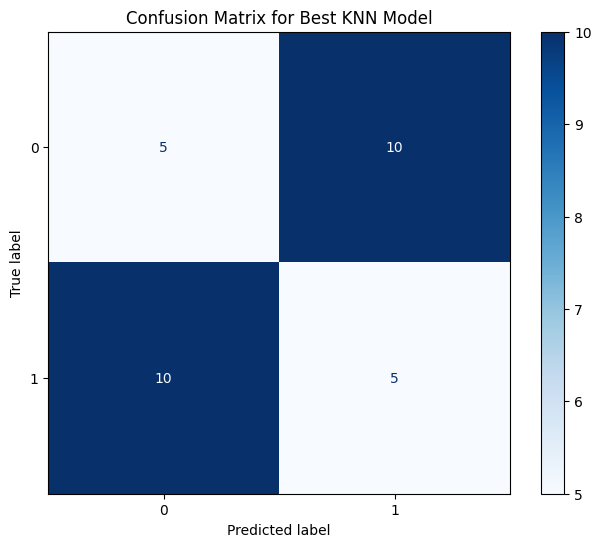

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

# Make predictions on the test set using the best KNN model
y_pred_knn = best_knn_model.predict(X_test_scaled_knn)

# Calculate F1-score, Precision, and Recall
knn_f1 = f1_score(y_test, y_pred_knn, average='weighted') # Use 'weighted' for multiclass if applicable, or 'binary' for binary
knn_precision = precision_score(y_test, y_pred_knn, average='weighted')
knn_recall = recall_score(y_test, y_pred_knn, average='weighted')

print(f"KNN F1-Score: {knn_f1:.4f}")
print(f"KNN Precision: {knn_precision:.4f}")
print(f"KNN Recall: {knn_recall:.4f}")

# Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(best_knn_model, X_test_scaled_knn, y_test, cmap=plt.cm.Blues, ax=ax)
ax.set_title('Confusion Matrix for Best KNN Model')
plt.show()

### 9.KNN Model Evaluation Metrics

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score

# Calculate F1-score, Precision, and Recall for the KNN model
knn_f1 = f1_score(y_test, y_pred_knn, average='weighted')
knn_precision = precision_score(y_test, y_pred_knn, average='weighted')
knn_recall = recall_score(y_test, y_pred_knn, average='weighted')

print(f"KNN F1-Score: {knn_f1:.4f}")
print(f"KNN Precision: {knn_precision:.4f}")
print(f"KNN Recall: {knn_recall:.4f}")

KNN F1-Score: 0.3333
KNN Precision: 0.3333
KNN Recall: 0.3333


### 10.ROC Curve for KNN Model

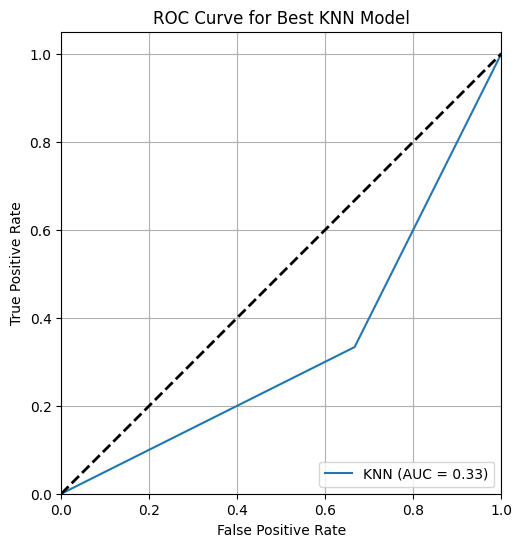

In [ ]:
from sklearn.metrics import RocCurveDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class (assuming binary classification)
# For multiclass, you might need to adapt this or plot one-vs-rest
if hasattr(best_knn_model, 'predict_proba'):
    y_pred_proba_knn = best_knn_model.predict_proba(X_test_scaled_knn)[:, 1]
else:
    # If the model doesn't have predict_proba, we can't plot ROC curve this way
    print("Model does not have 'predict_proba' method, cannot plot ROC curve.")
    # Fallback or alternative approach might be needed
    y_pred_proba_knn = None

if y_pred_proba_knn is not None:
    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba_knn)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.figure(figsize=(8, 6))
    RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='KNN').plot(ax=plt.gca())
    plt.title('ROC Curve for Best KNN Model')
    plt.plot([0, 1], [0, 1], 'k--', lw=2) # Add random guess line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.grid(True)
    plt.show()

### 11.ROC Curve for Decision Tree Model

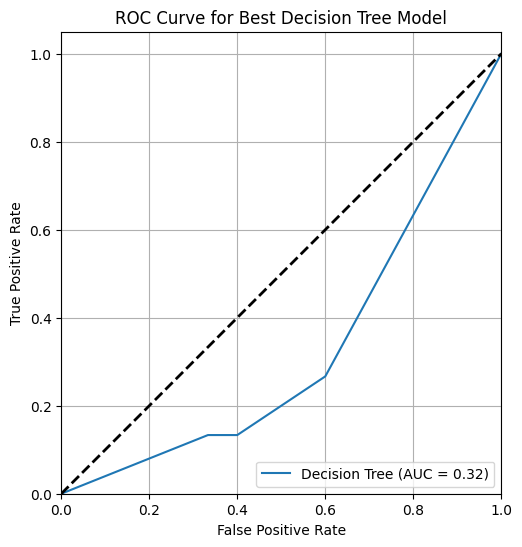

In [26]:
from sklearn.metrics import RocCurveDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class
if hasattr(best_dt_model, 'predict_proba'):
    y_pred_proba_dt = best_dt_model.predict_proba(X_test)[:, 1]
else:
    print("Decision Tree model does not have 'predict_proba' method, cannot plot ROC curve.")
    y_pred_proba_dt = None

if y_pred_proba_dt is not None:
    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba_dt)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.figure(figsize=(8, 6))
    RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Decision Tree').plot(ax=plt.gca())
    plt.title('ROC Curve for Best Decision Tree Model')
    plt.plot([0, 1], [0, 1], 'k--', lw=2) # Add random guess line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.grid(True)
    plt.show()

### 12.ROC Curve for Random Forest Model

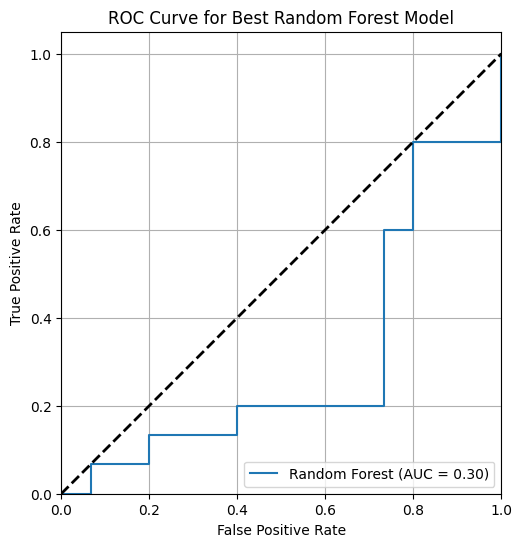

In [27]:
from sklearn.metrics import RocCurveDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class
if hasattr(best_rf_model, 'predict_proba'):
    y_pred_proba_rf = best_rf_model.predict_proba(X_test)[:, 1]
else:
    print("Random Forest model does not have 'predict_proba' method, cannot plot ROC curve.")
    y_pred_proba_rf = None

if y_pred_proba_rf is not None:
    # Calculate ROC curve and AUC
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba_rf)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.figure(figsize=(8, 6))
    RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Random Forest').plot(ax=plt.gca())
    plt.title('ROC Curve for Best Random Forest Model')
    plt.plot([0, 1], [0, 1], 'k--', lw=2) # Add random guess line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.grid(True)
    plt.show()

### 13.Comparison of Model Accuracies

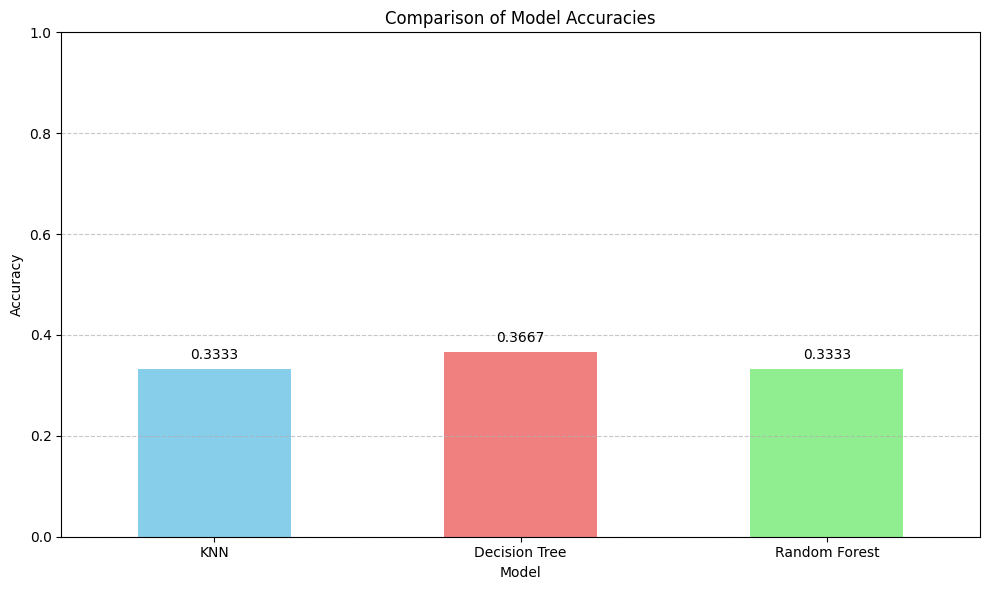

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a dictionary of model accuracies
model_accuracies = {
    'KNN': knn_best_accuracy,
    'Decision Tree': dt_best_accuracy,
    'Random Forest': rf_best_accuracy
}

# Convert to a pandas Series for easy plotting
accuracies_series = pd.Series(model_accuracies)

# Plot the accuracies
plt.figure(figsize=(10, 6))
ax = accuracies_series.plot(kind='bar', color=['skyblue', 'lightcoral', 'lightgreen'])
plt.title('Comparison of Model Accuracies')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1) # Accuracy scores range from 0 to 1
plt.xticks(rotation=0)

# Add accuracy values on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 14.LIME Explanation for Best Performing Model (Decision Tree)

Explaining prediction for instance 0 from the test set using Decision Tree model.
Actual class for this instance: 1


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(



LIME Explanation for Decision Tree:
[('feature_2 <= 0.22', -0.33432779172805366), ('0.26 < feature_5 <= 0.47', 0.15628613181283696), ('0.42 < feature_4 <= 0.64', -0.11547956877378898), ('0.23 < feature_8 <= 0.61', 0.10151109418187768), ('feature_6 > 0.63', 0.06848061249525536)]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


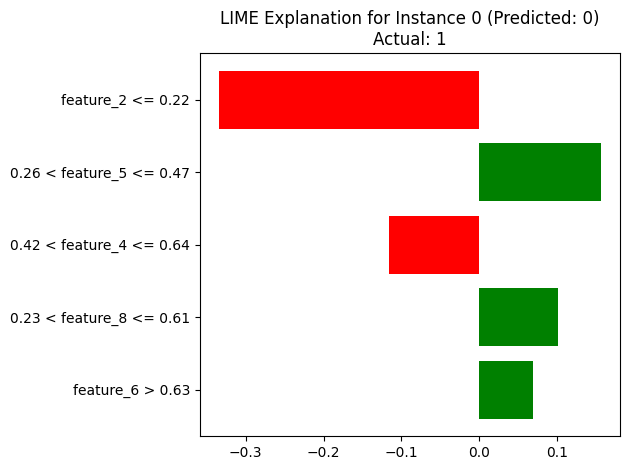

In [33]:
import lime
import lime.lime_tabular
import matplotlib.pyplot as plt

# Get feature names and class names
feature_names_dt = X_train.columns.tolist()
class_names_dt = [str(cls) for cls in best_dt_model.classes_]

# Initialize the LIME Tabular Explainer for the Decision Tree model
explainer_dt = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values, # LIME expects numpy array
    feature_names=feature_names_dt,
    class_names=class_names_dt,
    mode='classification'
)

# Choose an instance from the test set to explain (e.g., the first instance)
instance_idx_dt = 0
instance_to_explain_dt = X_test.iloc[instance_idx_dt].values

print(f"Explaining prediction for instance {instance_idx_dt} from the test set using Decision Tree model.")
print(f"Actual class for this instance: {y_test.iloc[instance_idx_dt]}")

# Generate an explanation for the instance
explanation_dt = explainer_dt.explain_instance(
    data_row=instance_to_explain_dt,
    predict_fn=best_dt_model.predict_proba, # LIME requires predict_proba
    num_features=5 # Explain using the top 5 most important features
)

# Print the explanation
print("\nLIME Explanation for Decision Tree:")
print(explanation_dt.as_list())

# Visualize the explanation in the notebook
fig_dt = explanation_dt.as_pyplot_figure()
plt.title(f"LIME Explanation for Instance {instance_idx_dt} (Predicted: {best_dt_model.predict([instance_to_explain_dt])[0]})\nActual: {y_test.iloc[instance_idx_dt]}")
plt.tight_layout()
plt.show()